
# Comparación de algoritmos de clasificación en Machine Learning

## Introducción

El objetivo de este proyecto es implementar y comparar cinco algoritmos de clasificación de Machine Learning utilizando una base de datos de instituciones prestadoras de servicios de salud (IPS) en Colombia.

Los algoritmos que se evaluarán son Decision Tree, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (K-NN) y Naive Bayes.

Se analizarán las métricas Accuracy, Precision, Recall y F1-score, así como las matrices de confusión, para identificar el modelo más adecuado para el problema de clasificación.


In [13]:

# Importar las librerías necesarias
import pandas as pd
import numpy as np

# Cargar el archivo CSV desde nuestro computador
from google.colab import files
archivos = files.upload()


Saving ips_colombia.csv to ips_colombia (1).csv


In [14]:

# Cargar la base de datos en un DataFrame
df = pd.read_csv("ips_colombia.csv", low_memory=False)

# Mostrar las dimensiones de la base de datos
print("Número de filas y columnas:", df.shape)

# Mostrar los nombres de las columnas
print("\nColumnas de la base de datos:")
print(df.columns.tolist())

# Mostrar los primeros cinco registros
print("\nPrimeros cinco registros:")
display(df.head())


Número de filas y columnas: (11466, 27)

Columnas de la base de datos:
['depa_nombre', 'muni_nombre', 'codigo_habilitacion', 'nombre_prestador', 'tido_codigo', 'nits_nit', 'razon_social', 'clpr_codigo', 'clpr_nombre', 'ese', 'direccion', 'telefono', 'fax', 'email', 'gerente', 'nivel', 'caracter', 'habilitado', 'fecha_radicacion', 'fecha_vencimiento', 'fecha_cierre', 'dv', 'clase_persona', 'naju_codigo', 'naju_nombre', 'numero_sede_principal', 'fecha_corte_REPS']

Primeros cinco registros:


,depa_nombre,muni_nombre,codigo_habilitacion,nombre_prestador,tido_codigo,nits_nit,razon_social,clpr_codigo,clpr_nombre,ese,...,habilitado,fecha_radicacion,fecha_vencimiento,fecha_cierre,dv,clase_persona,naju_codigo,naju_nombre,numero_sede_principal,fecha_corte_REPS
0,Amazonas,LETICIA,9100100019,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,NaN,838000096,E.S.E. HOSPITAL SAN RAFAEL DE LETICIA,1,Instituciones - IPS,SI,...,SI,20030409,20220831,NaN,7.0,JURIDICO,4,Pública,1.0,Fecha corte REPS: Jun 16 2022 2:33PM
1,Amazonas,LETICIA,9100100185,FREYA SKIN AND BODY CARE S.A.S TWO,NaN,901438650,FREYA SKIN AND BODY CARE S.A.S TWO,1,Instituciones - IPS,NaN,...,SI,20201221,20241220,NaN,7.0,JURIDICO,1,Privada,1.0,Fecha corte REPS: Jun 16 2022 2:33PM
2,Amazonas,LETICIA,9100100069,FUNDACION CLINICA LETICIA,NaN,900142282,FUNDACION CLINICA LETICIA,1,Instituciones - IPS,NO,...,SI,20070625,20220831,NaN,4.0,JURIDICO,1,Privada,1.0,Fecha corte REPS: Jun 16 2022 2:33PM
3,Amazonas,LETICIA,9100100158,IMPROVE QUALITY REDUCE COST SAVE LIFES AUDITOR...,NaN,900784482,IMPROVE QUALITY REDUCE COST SAVE LIFES AUDITOR...,1,Instituciones - IPS,NaN,...,SI,20161025,20230831,NaN,5.0,JURIDICO,1,Privada,1.0,Fecha corte REPS: Jun 16 2022 2:33PM
4,Amazonas,LETICIA,9100100144,"INSTITUTO PARA LA PREVENCIÓN, EL TRATAMIENTO Y...",NaN,900275974,"INSTITUTO PARA LA PREVENCIÓN, EL TRATAMIENTO Y...",1,Instituciones - IPS,NaN,...,SI,20151026,20220831,NaN,3.0,JURIDICO,1,Privada,1.0,Fecha corte REPS: Jun 16 2022 2:33PM


In [15]:

# 1. Revisar los tipos de datos de las columnas
print("TIPOS DE DATOS")
display(df.dtypes)

# 2. Contar los valores de la variable objetivo 'ese'
print("\nDISTRIBUCIÓN DE LA VARIABLE OBJETIVO: ESE")
print(df["ese"].value_counts(dropna=False))

# 3. Calcular los porcentajes de cada categoría, sin contar los valores vacíos
print("\nPORCENTAJES DE LAS CATEGORÍAS")
print(
    df["ese"].value_counts(normalize=True) * 100
)

# 4. Revisar la cantidad de datos faltantes por columna
print("\nDATOS FALTANTES POR COLUMNA")
faltantes = df.isnull().sum().sort_values(ascending=False)
display(faltantes[faltantes > 0])

# 5. Revisar los valores únicos de la variable objetivo
print("\nVALORES ÚNICOS DE ESE")
print(df["ese"].dropna().unique())


TIPOS DE DATOS


,0
depa_nombre,object
muni_nombre,object
codigo_habilitacion,int64
nombre_prestador,object
tido_codigo,float64
nits_nit,int64
razon_social,object
clpr_codigo,int64
clpr_nombre,object
ese,object



DISTRIBUCIÓN DE LA VARIABLE OBJETIVO: ESE
ese
NaN    7965
NO     2569
SI      932
Name: count, dtype: int64

PORCENTAJES DE LAS CATEGORÍAS
ese
NO    73.379035
SI    26.620965
Name: proportion, dtype: float64

DATOS FALTANTES POR COLUMNA


,0
tido_codigo,11466
gerente,11466
fecha_cierre,11465
nivel,10464
caracter,10457
ese,7965
fax,6739
email,14
telefono,13
numero_sede_principal,11



VALORES ÚNICOS DE ESE
['SI' 'NO']


In [16]:

# PASO 6: Preparación inicial de los datos

# Conservar solo los registros que tienen una categoría ESE conocida
df_model = df.dropna(subset=["ese"]).copy()

# Confirmar que la variable objetivo tenga únicamente SI y NO
df_model["ese"] = df_model["ese"].str.strip().str.upper()

df_model = df_model[df_model["ese"].isin(["SI", "NO"])].copy()

# Convertir las fechas al formato correcto
for columna in ["fecha_radicacion", "fecha_vencimiento"]:
    fecha = pd.to_datetime(
        df_model[columna].astype("Int64").astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    df_model[f"{columna}_anio"] = fecha.dt.year
    df_model[f"{columna}_mes"] = fecha.dt.month

# Definir las variables de entrada
columnas_entrada = [
    "depa_nombre",
    "muni_nombre",
    "clpr_nombre",
    "clase_persona",
    "habilitado",
    "fecha_radicacion_anio",
    "fecha_radicacion_mes",
    "fecha_vencimiento_anio",
    "fecha_vencimiento_mes",
    "numero_sede_principal"
]

# Crear la tabla final de trabajo
X = df_model[columnas_entrada].copy()
y = df_model["ese"].copy()

# Mostrar las dimensiones y la distribución de las clases
print("Dimensiones de las variables de entrada:", X.shape)
print("Número de etiquetas:", y.shape[0])

print("\nDistribución de la variable objetivo:")
display(y.value_counts().to_frame("Cantidad"))

print("\nPrimeros cinco registros de las variables de entrada:")
display(X.head())


Dimensiones de las variables de entrada: (3501, 10)
Número de etiquetas: 3501

Distribución de la variable objetivo:


,Cantidad
ese,
NO,2569
SI,932



Primeros cinco registros de las variables de entrada:


,depa_nombre,muni_nombre,clpr_nombre,clase_persona,habilitado,fecha_radicacion_anio,fecha_radicacion_mes,fecha_vencimiento_anio,fecha_vencimiento_mes,numero_sede_principal
0,Amazonas,LETICIA,Instituciones - IPS,JURIDICO,SI,2003,4,2022,8,1.0
2,Amazonas,LETICIA,Instituciones - IPS,JURIDICO,SI,2007,6,2022,8,1.0
6,Amazonas,LETICIA,Instituciones - IPS,JURIDICO,SI,2017,11,2022,11,1.0
7,Amazonas,LETICIA,Instituciones - IPS,JURIDICO,SI,2017,8,2022,8,1.0
14,Antioquia,ABEJORRAL,Instituciones - IPS,JURIDICO,SI,2011,7,2023,8,1.0


In [17]:

# PASO 7: División y preparación de los datos

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identificar columnas categóricas y numéricas
columnas_categoricas = X.select_dtypes(include=["object"]).columns.tolist()
columnas_numericas = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Variables categóricas:", columnas_categoricas)
print("Variables numéricas:", columnas_numericas)

# Dividir los datos: 80 % entrenamiento y 20 % prueba
# stratify conserva aproximadamente la proporción de SI y NO
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTamaño de entrenamiento:", X_train.shape)
print("Tamaño de prueba:", X_test.shape)

# Preparar las variables categóricas
preparacion_categoricas = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Preparar las variables numéricas
preparacion_numericas = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Unir ambas preparaciones
preprocesador = ColumnTransformer(transformers=[
    ("categoricas", preparacion_categoricas, columnas_categoricas),
    ("numericas", preparacion_numericas, columnas_numericas)
])

print("\nPreprocesador configurado correctamente.")


Variables categóricas: ['depa_nombre', 'muni_nombre', 'clpr_nombre', 'clase_persona', 'habilitado']
Variables numéricas: ['fecha_radicacion_anio', 'fecha_radicacion_mes', 'fecha_vencimiento_anio', 'fecha_vencimiento_mes', 'numero_sede_principal']

Tamaño de entrenamiento: (2800, 10)
Tamaño de prueba: (701, 10)

Preprocesador configurado correctamente.


In [18]:

# PASO 8: Entrenamiento de los cinco algoritmos

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Definir los cinco modelos
modelos = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "SVM": SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ),

    "K-NN": KNeighborsClassifier(
        n_neighbors=5
    ),


}

# Entrenar cada modelo utilizando el mismo conjunto de entrenamiento
modelos_entrenados = {}

for nombre, algoritmo in modelos.items():

    # Crear una tubería independiente para cada modelo
    tuberia = Pipeline(steps=[
        ("preprocesamiento", clone(preprocesador)),
        ("modelo", algoritmo)
    ])

    print(f"Entrenando {nombre}...")

    tuberia.fit(X_train, y_train)

    modelos_entrenados[nombre] = tuberia

    print(f"{nombre} entrenado correctamente.\n")

print("Entrenamiento finalizado para los cuatro algoritmos.")


Entrenando Decision Tree...
Decision Tree entrenado correctamente.

Entrenando Random Forest...
Random Forest entrenado correctamente.

Entrenando SVM...
SVM entrenado correctamente.

Entrenando K-NN...
K-NN entrenado correctamente.

Entrenamiento finalizado para los cuatro algoritmos.


In [19]:

# Corregir y entrenar el modelo Naive Bayes

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB

# Crear un preprocesador que genere una matriz densa
preparacion_categoricas_densa = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preparacion_numericas_nb = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

preprocesador_nb = ColumnTransformer(transformers=[
    ("categoricas", preparacion_categoricas_densa, columnas_categoricas),
    ("numericas", preparacion_numericas_nb, columnas_numericas)
])

# Crear y entrenar la tubería de Naive Bayes
modelo_nb = Pipeline(steps=[
    ("preprocesamiento", preprocesador_nb),
    ("modelo", GaussianNB())
])

modelo_nb.fit(X_train, y_train)

# Guardar el modelo entrenado en el diccionario
modelos_entrenados["Naive Bayes"] = modelo_nb

print("Naive Bayes entrenado correctamente.")
print("Los cinco modelos están listos para la evaluación.")


Naive Bayes entrenado correctamente.
Los cinco modelos están listos para la evaluación.


In [20]:

# PASO 9: Evaluación de los cinco modelos

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Guardar las predicciones y los resultados
predicciones = {}
resultados = []

for nombre, modelo in modelos_entrenados.items():

    # Predecir las categorías del conjunto de prueba
    y_pred = modelo.predict(X_test)
    predicciones[nombre] = y_pred

    # Calcular las métricas, tomando SI como clase positiva
    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="SI", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="SI", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, pos_label="SI", zero_division=0
        )
    })

# Crear una tabla comparativa
tabla_resultados = pd.DataFrame(resultados)
tabla_resultados = tabla_resultados.sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)

print("COMPARACIÓN DE MÉTRICAS")
display(tabla_resultados.round(4))

# Mostrar el reporte detallado de cada modelo
for nombre, y_pred in predicciones.items():
    print(f"\nREPORTE DE CLASIFICACIÓN: {nombre}")
    print(classification_report(
        y_test,
        y_pred,
        labels=["NO", "SI"],
        zero_division=0
    ))


COMPARACIÓN DE MÉTRICAS


,Modelo,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.8959,0.8000,0.8128,0.8064
1,Decision Tree,0.8673,0.7282,0.8021,0.7634
2,SVM,0.8274,0.6269,0.8717,0.7293
3,K-NN,0.8317,0.8000,0.4920,0.6093
4,Naive Bayes,0.7375,0.5484,0.0909,0.1560



REPORTE DE CLASIFICACIÓN: Decision Tree
              precision    recall  f1-score   support

          NO       0.93      0.89      0.91       514
          SI       0.73      0.80      0.76       187

    accuracy                           0.87       701
   macro avg       0.83      0.85      0.84       701
weighted avg       0.87      0.87      0.87       701


REPORTE DE CLASIFICACIÓN: Random Forest
              precision    recall  f1-score   support

          NO       0.93      0.93      0.93       514
          SI       0.80      0.81      0.81       187

    accuracy                           0.90       701
   macro avg       0.87      0.87      0.87       701
weighted avg       0.90      0.90      0.90       701


REPORTE DE CLASIFICACIÓN: SVM
              precision    recall  f1-score   support

          NO       0.95      0.81      0.87       514
          SI       0.63      0.87      0.73       187

    accuracy                           0.83       701
   macro avg   

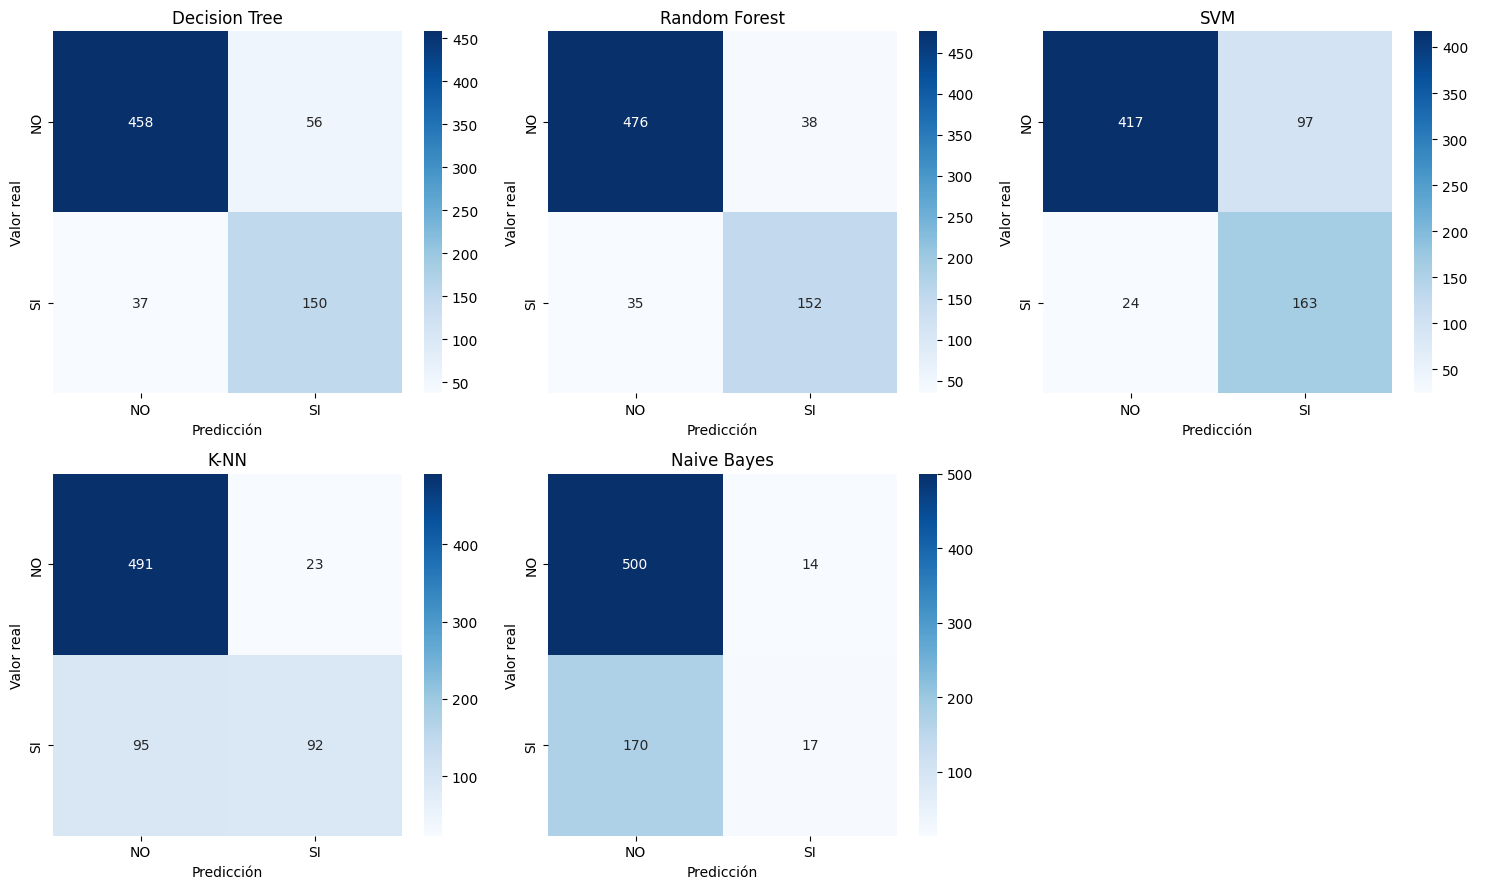

In [21]:

# PASO 10: Matrices de confusión

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (nombre, y_pred) in enumerate(predicciones.items()):

    # Ordenar las categorías para facilitar la comparación
    matriz = confusion_matrix(
        y_test, y_pred, labels=["NO", "SI"]
    )

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["NO", "SI"],
        yticklabels=["NO", "SI"],
        ax=axes[i]
    )

    axes[i].set_title(nombre)
    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Valor real")

# Ocultar el espacio sobrante
axes[-1].axis("off")

plt.tight_layout()
plt.show()



## Análisis e interpretación de resultados

Los resultados muestran diferencias importantes entre los cinco algoritmos de clasificación. Random Forest obtuvo el mejor desempeño general, con un Accuracy de 89,59 %, Precision de 80,00 %, Recall de 81,28 % y F1-score de 80,64 % para la clase positiva SI.

Decision Tree también presentó un buen rendimiento, con un F1-score de 76,34 % para la clase SI. SVM alcanzó un Recall de 87,17 %, lo que indica que identificó una proporción alta de los registros positivos, aunque tuvo más falsos positivos. K-NN presentó un Recall de 49,20 %, mientras que Naive Bayes obtuvo un Recall de apenas 9,09 %, mostrando dificultades para reconocer la clase SI.

Las matrices de confusión respaldan estos resultados. Random Forest identificó correctamente 152 de los 187 registros positivos y clasificó correctamente 476 de los 514 registros negativos.

En conclusión, Random Forest es el modelo recomendado entre los cinco evaluados, porque ofrece el mejor equilibrio entre las métricas analizadas. Sin embargo, estos resultados corresponden a la base disponible y no garantizan el mismo desempeño con otras instituciones o datos futuros.


15 VARIABLES MÁS IMPORTANTES


,Variable,Importancia
736,numericas__fecha_radicacion_anio,0.1282
737,numericas__fecha_radicacion_mes,0.0834
101,categoricas__muni_nombre_BOGOTÁ,0.0652
5,categoricas__depa_nombre_Bogotá D.C,0.0642
373,categoricas__muni_nombre_MEDELLÍN,0.0483
740,numericas__numero_sede_principal,0.0257
121,categoricas__muni_nombre_CALI,0.0218
738,numericas__fecha_vencimiento_anio,0.0211
105,categoricas__muni_nombre_BUCARAMANGA,0.0172
92,categoricas__muni_nombre_BARRANQUILLA,0.0171


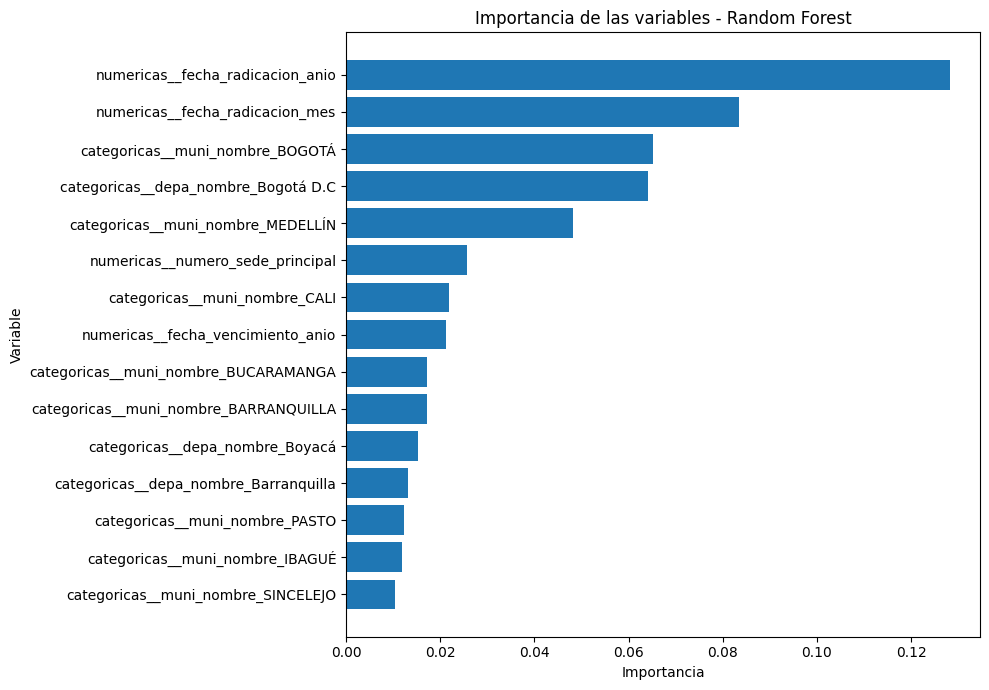

In [22]:

# PASO 14: Importancia de las variables en Random Forest

import pandas as pd
import matplotlib.pyplot as plt

# Obtener el modelo Random Forest ya entrenado
rf = modelos_entrenados["Random Forest"]

# Recuperar los nombres de las variables después del preprocesamiento
nombres_variables = (
    rf.named_steps["preprocesamiento"].get_feature_names_out()
)

# Obtener la importancia de cada variable
importancias = rf.named_steps["modelo"].feature_importances_

# Organizar las variables de mayor a menor importancia
tabla_importancias = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": importancias
}).sort_values(by="Importancia", ascending=False)

# Mostrar las 15 variables más importantes
print("15 VARIABLES MÁS IMPORTANTES")
display(tabla_importancias.head(15).round(4))

# Graficar las 15 variables principales
top_variables = tabla_importancias.head(15).sort_values(
    by="Importancia", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_variables["Variable"], top_variables["Importancia"])
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.title("Importancia de las variables - Random Forest")
plt.tight_layout()
plt.show()



## Importancia de las variables

El análisis de importancia de variables del modelo Random Forest muestra que el año de radicación fue la característica con mayor importancia (0,1282), seguido del mes de radicación (0,0834). También destacaron algunas categorías geográficas, como Bogotá y Medellín.

Estos resultados indican que las fechas y la ubicación aportan información relevante para las predicciones realizadas por el modelo. Sin embargo, la importancia de una variable no implica una relación causal con la condición ESE.

Es necesario interpretar estos resultados con precaución, ya que los patrones identificados pueden depender de la composición y las características de la base de datos utilizada. Por lo tanto, el modelo se considera una herramienta de análisis académico y no un mecanismo para determinar oficialmente la condición jurídica de una IPS.



## Conclusiones

En este proyecto se implementaron y compararon cinco algoritmos de clasificación: Decision Tree, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (K-NN) y Naive Bayes. Para garantizar una comparación justa, todos los modelos utilizaron los mismos conjuntos de entrenamiento y prueba.

Random Forest obtuvo el mejor desempeño general, con un Accuracy de 89,59 % y un F1-score de 0,8064 para la categoría SI. Estos resultados indican que logró un buen equilibrio entre la precisión de sus predicciones y la identificación de las instituciones etiquetadas como ESE. Decision Tree también presentó resultados favorables, mientras que SVM obtuvo el mayor Recall para la categoría SI. Por su parte, K-NN y Naive Bayes mostraron mayores dificultades para identificar esta categoría.

El análisis de importancia de variables mostró que el año y el mes de radicación, junto con algunas características geográficas, tuvieron una contribución relevante en las predicciones de Random Forest.

Se concluye que Random Forest es el modelo más adecuado entre los cinco evaluados para este ejercicio, de acuerdo con las métricas obtenidas. Sin embargo, los resultados dependen de la calidad y las características de los datos disponibles. El modelo reproduce patrones de las etiquetas existentes y no determina oficialmente la condición jurídica de una IPS.

Finalmente, esta actividad permitió comprender la importancia de preparar los datos, evaluar diferentes algoritmos mediante métricas complementarias e interpretar los resultados antes de seleccionar un modelo de Machine Learning.
